
# Factor Strategy Construction

## Objective

This notebook extends the previous analysis of stock performance, risk, diversification, and portfolio optimization by constructing systematic factor-based investment strategies.

We investigate two widely studied equity factors:

1. **Momentum:** Stocks that have performed relatively well in the past may continue to outperform over subsequent periods.
2. **Low Volatility:** Stocks with lower historical return volatility may provide a less volatile investment strategy.

Using historical adjusted closing prices for Reliance Industries, TCS, Infosys, HDFC Bank, and ICICI Bank, we will prepare the data required to construct and evaluate these strategies.

The analysis will follow a systematic process:

- Collect and preprocess historical stock-price data.
- Calculate daily and monthly returns.
- Define momentum and low-volatility signals using historical information.
- Rank stocks and construct factor-based portfolios.
- Establish a consistent rebalancing procedure.
- Compare the strategies with an equal-weight portfolio benchmark.

## Methodology

The strategies will be constructed using explicit ranking rules rather than subjective stock selection. Portfolio formation will use information available at the time of each investment decision to reduce look-ahead bias.

The initial analysis will focus on strategy construction. Performance evaluation, transaction costs, and out-of-sample testing will be addressed in subsequent sections.

**Data period:** January 2020 to December 2025.

**Data source:** Yahoo Finance, accessed through the `yfinance` Python library.

**Stock universe:** Reliance Industries, TCS, Infosys, HDFC Bank, and ICICI Bank.


In [1]:

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Define the stock universe
stocks = [
    "RELIANCE.NS",
    "TCS.NS",
    "INFY.NS",
    "HDFCBANK.NS",
    "ICICIBANK.NS"
]

# Define the historical data period
start_date = "2020-01-01"
end_date = "2026-01-01"  # End date is exclusive

# Download historical stock-price data
data = yf.download(
    stocks,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

# Check whether the download was successful
if data.empty:
    raise ValueError(
        "No data was downloaded. Check your internet connection, "
        "ticker symbols, or date range."
    )

# Extract adjusted closing prices
# With auto_adjust=True, the Close column is adjusted
# for corporate actions.
if isinstance(data.columns, pd.MultiIndex):
    if "Close" in data.columns.get_level_values(0):
        close_prices = data["Close"]
    elif "Close" in data.columns.get_level_values(1):
        close_prices = data.xs(
            "Close", axis=1, level=1
        )
    else:
        raise KeyError(
            "Could not find the Close price field in downloaded data."
        )
else:
    close_prices = data[["Close"]].rename(
        columns={"Close": stocks[0]}
    )

# Keep the same stock order as the previous notebooks
close_prices = close_prices.reindex(columns=stocks)

# Remove rows where every stock price is missing
close_prices = close_prices.dropna(how="all")

# Check that every stock has usable price observations
missing_stocks = [
    stock for stock in stocks
    if close_prices[stock].notna().sum() == 0
]

if missing_stocks:
    raise ValueError(
        f"No valid price data found for: {missing_stocks}"
    )

# Display a preview of the downloaded data
print("Downloaded stock-price data successfully.")
print(f"Start date: {close_prices.index.min().date()}")
print(f"End date:   {close_prices.index.max().date()}")
print(f"Number of observations: {len(close_prices)}")
print(f"Number of stocks: {len(stocks)}")

display(close_prices.head())


Downloaded stock-price data successfully.
Start date: 2020-01-01
End date:   2025-12-31
Number of observations: 1487
Number of stocks: 5


Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Date,,,,,
2020-01-01,672.216125,1821.426636,619.740295,595.677246,514.797913
2020-01-02,683.660339,1813.065796,617.932129,599.474121,518.490479
2020-01-03,684.483948,1849.198120,627.436035,590.925293,516.812012
2020-01-06,668.609375,1849.030518,621.422424,578.136719,504.199890
2020-01-07,678.895630,1853.568359,612.212830,587.291321,501.514374



## 1. Introduction to Factor Investing

Factor investing is an investment approach in which stocks are selected and weighted according to measurable characteristics, known as factors, that may help explain differences in their returns or risk.

Instead of relying on subjective stock selection, factor-based strategies use systematic rules to rank securities and construct portfolios.

In this notebook, we examine two factors: momentum and low volatility.

### 1.1 Momentum Factor

The momentum factor is based on the observation that stocks with relatively strong past performance may continue to outperform stocks with relatively weak past performance over a subsequent period.

For a stock \(i\), its momentum signal can be defined using its historical cumulative return over a lookback period of \(L\) trading days:

$$
M_{i,t} = \frac{P_{i,t}}{P_{i,t-L}} - 1
$$

where:

- \(P_{i,t}\) is the adjusted closing price of stock \(i\) at time \(t\).
- \(L\) is the lookback period.
- \(M_{i,t}\) is the momentum signal.

For the strategy developed in this notebook, we will use a momentum signal that excludes the most recent month. This helps reduce the influence of short-term return reversals.

### 1.2 Low-Volatility Factor

The low-volatility factor ranks stocks according to the variability of their historical returns. Stocks with lower estimated volatility receive higher rankings under this strategy.

Let \(r_{i,t}\) denote the daily return of stock \(i\). Its historical volatility over a rolling window of \(L\) observations is estimated as:

$$
\sigma_{i,t} =
\sqrt{\frac{1}{L-1}
\sum_{j=1}^{L}
(r_{i,t-j}-\bar r_{i,t})^2}
$$

where \(\bar r_{i,t}\) is the mean return over the estimation window.

Stocks with lower estimated volatility are preferred by the low-volatility strategy.

### 1.3 Portfolio Construction

At each rebalancing date, the stocks will be ranked using their respective factor signals. A fixed number of top-ranked stocks will then be selected and assigned equal weights.

The resulting strategies will be compared with an equal-weight portfolio benchmark.

### 1.4 Important Considerations

Factor signals must be calculated using only information available at the portfolio formation date. The backtest must also account for the timing of trades, rebalancing frequency, and transaction costs where applicable.

Historical factor performance does not guarantee future returns. The purpose of this analysis is to evaluate systematic investment rules, not to guarantee profitability.


Daily return summary statistics:


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
RELIANCE.NS,1486.0,0.000726,0.017810,-0.131539,-0.008392,0.000723,0.008513,0.147180
TCS.NS,1486.0,0.000464,0.014970,-0.094104,-0.006856,0.000064,0.007741,0.098451
INFY.NS,1486.0,0.000779,0.017263,-0.100393,-0.008452,0.000697,0.009622,0.120334
HDFCBANK.NS,1486.0,0.000463,0.016173,-0.126069,-0.007154,0.000586,0.007725,0.115996
ICICIBANK.NS,1486.0,0.000816,0.018717,-0.178479,-0.007192,0.000802,0.008726,0.137624


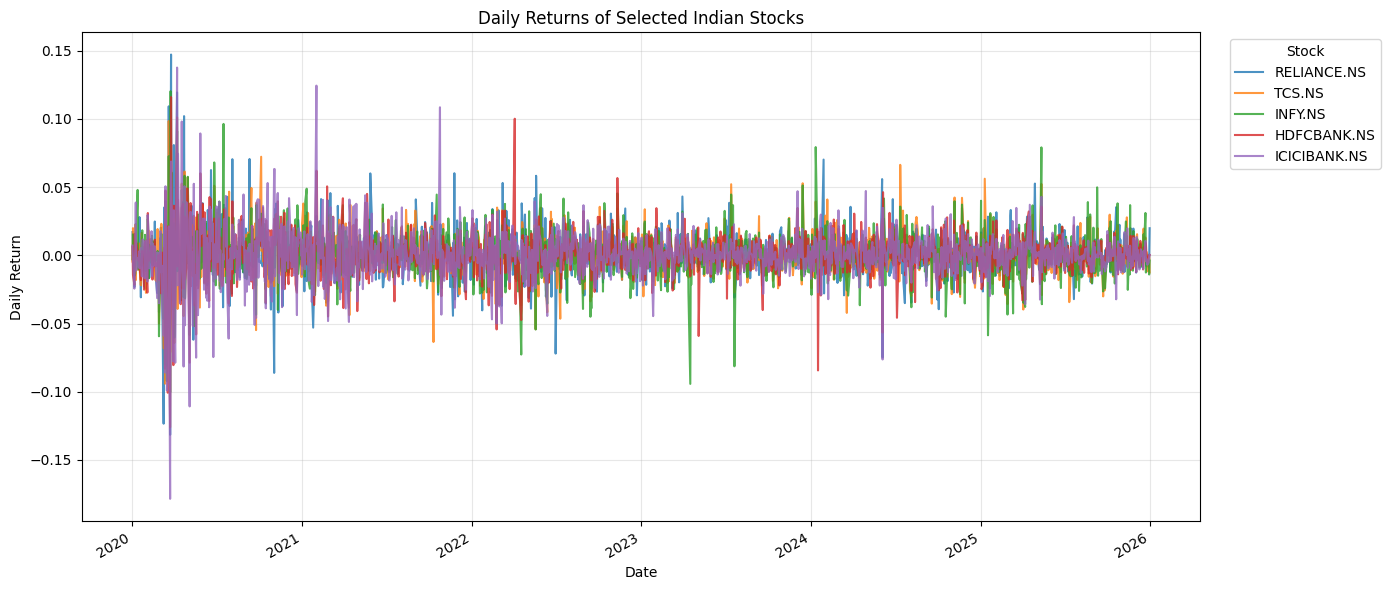

In [2]:

# Calculate daily simple returns
daily_returns = close_prices.pct_change(fill_method=None)

# Remove rows where all stock returns are missing
daily_returns = daily_returns.dropna(how="all")

# Display summary statistics
print("Daily return summary statistics:")
display(daily_returns.describe().T)

# Plot daily returns
daily_returns.plot(
    figsize=(14, 6),
    title="Daily Returns of Selected Indian Stocks",
    alpha=0.8
)

plt.xlabel("Date")
plt.ylabel("Daily Return")
plt.grid(True, alpha=0.3)
plt.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



## 2. Momentum Factor Construction

The momentum strategy ranks stocks according to their historical performance. Stocks with stronger momentum signals receive higher rankings and are preferred for portfolio inclusion.

### 2.1 Lookback Period and Skip Period

A common momentum specification uses approximately 12 months of historical returns while excluding the most recent month. This avoids relying too heavily on very recent price movements, which may exhibit short-term reversal effects.

In this notebook, we approximate these periods using daily trading observations:

- **Lookback period:** 252 trading days.
- **Skip period:** 21 trading days.
- **Signal:** cumulative return over the lookback window, excluding the skip period.

The momentum signal at time \(t\) is:

$$
M_{i,t} =
\frac{P_{i,t-21}}{P_{i,t-252}} - 1
$$

where \(P_{i,t}\) denotes the adjusted closing price of stock \(i\) at time \(t\).

A positive signal indicates a price increase over the measurement period, while a negative signal indicates a decline.

### 2.2 Ranking Stocks

At each date, stocks can be ranked from highest to lowest momentum. The highest-ranked stocks are candidates for inclusion in the momentum portfolio.

The signal requires sufficient historical observations. Therefore, the strategy will not generate a valid momentum ranking at the beginning of the sample.

**Implementation note:** The signal calculated at a given date uses prices available by that date. In the backtest, portfolio weights must be applied only to returns occurring after the signal is observed.


Latest common signal date: 2025-12-31
Momentum ranking (highest signal first):


,Momentum Signal,Rank
Ticker,,
RELIANCE.NS,0.292470,1
HDFCBANK.NS,0.134324,2
ICICIBANK.NS,0.079760,3
INFY.NS,-0.155769,4
TCS.NS,-0.222280,5


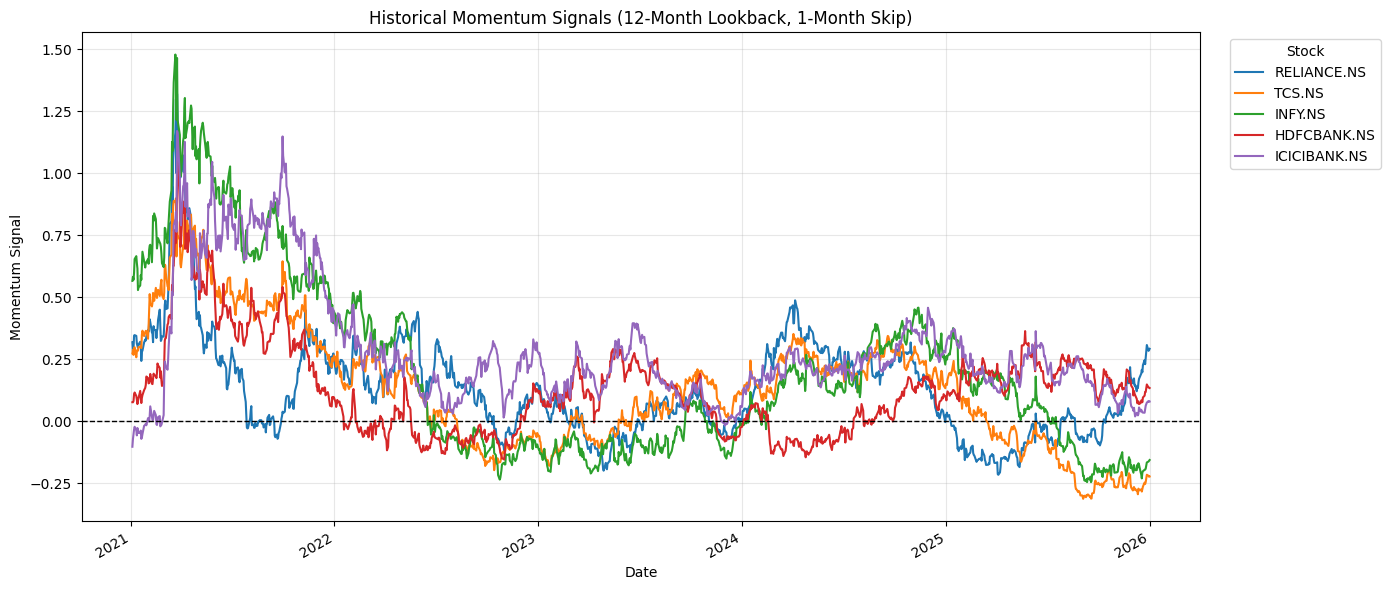

In [3]:

# Define the momentum lookback and skip periods
lookback_days = 252
skip_days = 21

# Calculate the momentum signal:
# price 21 trading days ago / price 252 trading days ago - 1
momentum_signal = (
    close_prices.shift(skip_days)
    / close_prices.shift(lookback_days)
    - 1
)

# Remove dates where no stock has a valid momentum signal
momentum_signal = momentum_signal.dropna(how="all")

# Find the latest date with a valid signal for every stock
valid_momentum = momentum_signal.dropna(how="any")

if valid_momentum.empty:
    raise ValueError(
        "Insufficient common historical data to calculate "
        "the momentum signal for all stocks."
    )

latest_signal_date = valid_momentum.index[-1]
latest_momentum = valid_momentum.loc[latest_signal_date]

# Rank stocks from highest to lowest momentum
momentum_ranking = (
    latest_momentum
    .sort_values(ascending=False)
    .rename("Momentum Signal")
    .to_frame()
)

momentum_ranking["Rank"] = (
    momentum_ranking["Momentum Signal"]
    .rank(ascending=False, method="min")
    .astype(int)
)

print(f"Latest common signal date: {latest_signal_date.date()}")
print("Momentum ranking (highest signal first):")

display(momentum_ranking)

# Plot historical momentum signals
momentum_signal.plot(
    figsize=(14, 6),
    title="Historical Momentum Signals (12-Month Lookback, 1-Month Skip)"
)

plt.axhline(0, color="black", linewidth=1, linestyle="--")
plt.xlabel("Date")
plt.ylabel("Momentum Signal")
plt.grid(True, alpha=0.3)
plt.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



## 3. Low-Volatility Factor Construction

The low-volatility strategy selects stocks based on the variability of their historical returns. It assigns higher rankings to stocks with lower estimated volatility.

Unlike the momentum strategy, which focuses on past price performance, this strategy focuses on the risk associated with past price movements.

### 3.1 Rolling Volatility

Let \(r_{i,t}\) denote the daily return of stock \(i\). The rolling volatility over a window of \(L\) trading days is estimated using the sample standard deviation:

$$
\sigma_{i,t} =
\sqrt{\frac{1}{L-1}
\sum_{j=0}^{L-1}
(r_{i,t-j}-\bar r_{i,t})^2}
$$

where \(\bar r_{i,t}\) is the mean daily return over the rolling window.

In this notebook, we use a window of 63 trading days, approximately one quarter of a trading year. This provides a relatively recent estimate of each stock's realized volatility.

### 3.2 Ranking Stocks

At each date, stocks are ranked from lowest to highest rolling volatility. The stock with the lowest estimated volatility receives Rank 1 and is preferred by the strategy.

The volatility signal is calculated using historical daily returns only. For portfolio backtesting, the signal will be shifted appropriately so that portfolio weights are determined before the returns to which they are applied.

### 3.3 Interpretation and Limitations

Low historical volatility does not necessarily imply low future risk. Volatility can change over time, and a low-volatility strategy may underperform during some market conditions.

The purpose of this analysis is to construct a transparent, rule-based strategy that can later be compared with momentum and an equal-weight benchmark.


Latest common signal date: 2025-12-31
Low-volatility ranking (lowest volatility first):


,Daily Volatility,Rank
Ticker,,
HDFCBANK.NS,0.006961,1
ICICIBANK.NS,0.009119,2
RELIANCE.NS,0.009469,3
TCS.NS,0.010318,4
INFY.NS,0.012749,5


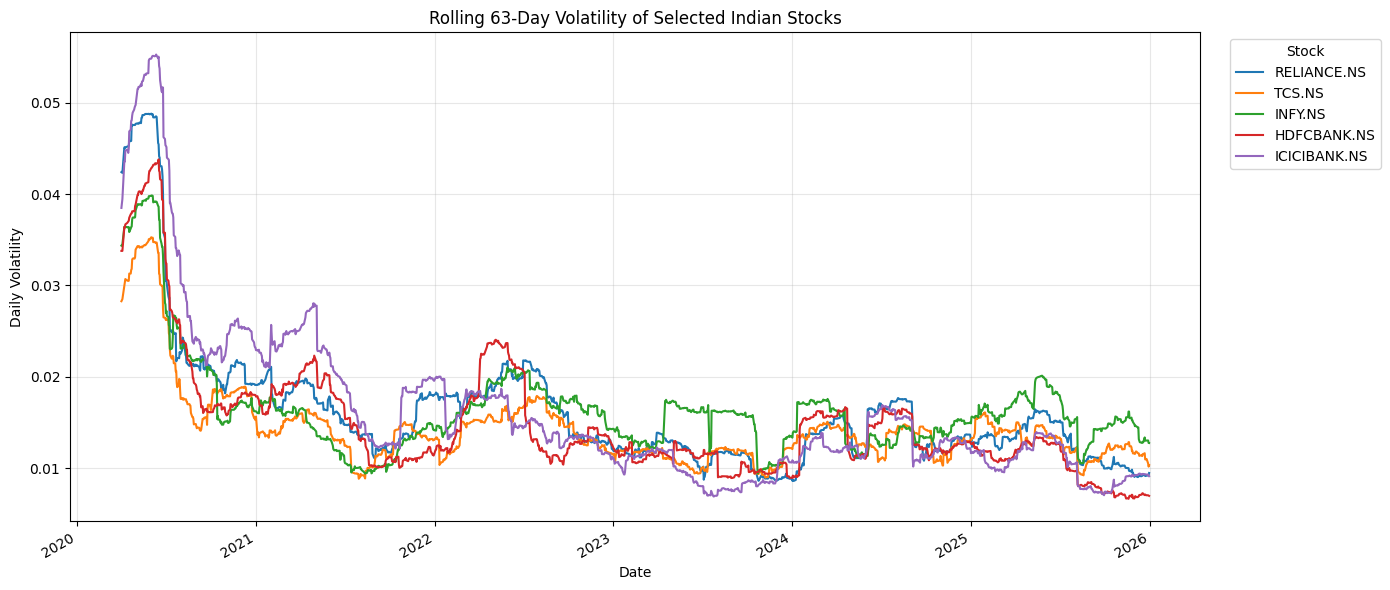

In [4]:

# Define the rolling volatility window
volatility_window = 63

# Calculate rolling standard deviation of daily returns
rolling_volatility = daily_returns.rolling(
    window=volatility_window,
    min_periods=volatility_window
).std()

# Remove dates where no stock has a valid volatility estimate
rolling_volatility = rolling_volatility.dropna(how="all")

# Find the latest date with a valid volatility estimate for every stock
valid_volatility = rolling_volatility.dropna(how="any")

if valid_volatility.empty:
    raise ValueError(
        "Insufficient common historical data to calculate "
        "rolling volatility for all stocks."
    )

latest_volatility_date = valid_volatility.index[-1]
latest_volatility = valid_volatility.loc[latest_volatility_date]

# Rank from lowest volatility to highest volatility
volatility_ranking = (
    latest_volatility
    .sort_values(ascending=True)
    .rename("Daily Volatility")
    .to_frame()
)

volatility_ranking["Rank"] = (
    volatility_ranking["Daily Volatility"]
    .rank(ascending=True, method="min")
    .astype(int)
)

print(f"Latest common signal date: {latest_volatility_date.date()}")
print("Low-volatility ranking (lowest volatility first):")

display(volatility_ranking)

# Plot rolling volatility
rolling_volatility.plot(
    figsize=(14, 6),
    title="Rolling 63-Day Volatility of Selected Indian Stocks"
)

plt.xlabel("Date")
plt.ylabel("Daily Volatility")
plt.grid(True, alpha=0.3)
plt.legend(title="Stock", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



## 4. Portfolio Construction

In this section, we construct three portfolios using predefined investment rules.

### 4.1 Equal-Weight Benchmark

The equal-weight portfolio allocates the same proportion of capital to each of the five stocks:

$$
w_i = \frac{1}{N} = \frac{1}{5} = 0.20
$$

where \(N\) is the number of stocks and \(w_i\) is the portfolio weight of stock \(i\).

This portfolio serves as a simple benchmark for evaluating the factor strategies.

### 4.2 Momentum Portfolio

At each monthly rebalancing date, stocks are ranked in descending order of their momentum signals. The two highest-ranked stocks are selected and assigned equal weights of 50% each.

### 4.3 Low-Volatility Portfolio

At each monthly rebalancing date, stocks are ranked in ascending order of their rolling volatility estimates. The two stocks with the lowest estimated volatility are selected and assigned equal weights of 50% each.

### 4.4 Rebalancing and Timing

The factor portfolios are rebalanced monthly. Signals are calculated using information available at the signal date, and the resulting portfolio weights are applied from the next trading day.

This one-day shift helps prevent look-ahead bias: a portfolio cannot earn a return that occurred before its weights were determined.

The portfolios are long-only and fully invested whenever valid signals are available. Transaction costs and market impact are not yet included, so the results should be interpreted as preliminary strategy simulations.


Latest target portfolio allocations:


,Equal-Weight,Momentum,Low-Volatility
RELIANCE.NS,0.2,0.5,0.0
TCS.NS,0.2,0.0,0.0
INFY.NS,0.2,0.0,0.0
HDFCBANK.NS,0.2,0.5,0.5
ICICIBANK.NS,0.2,0.0,0.5



Momentum portfolio weight sum: 1.0
Low-volatility portfolio weight sum: 1.0


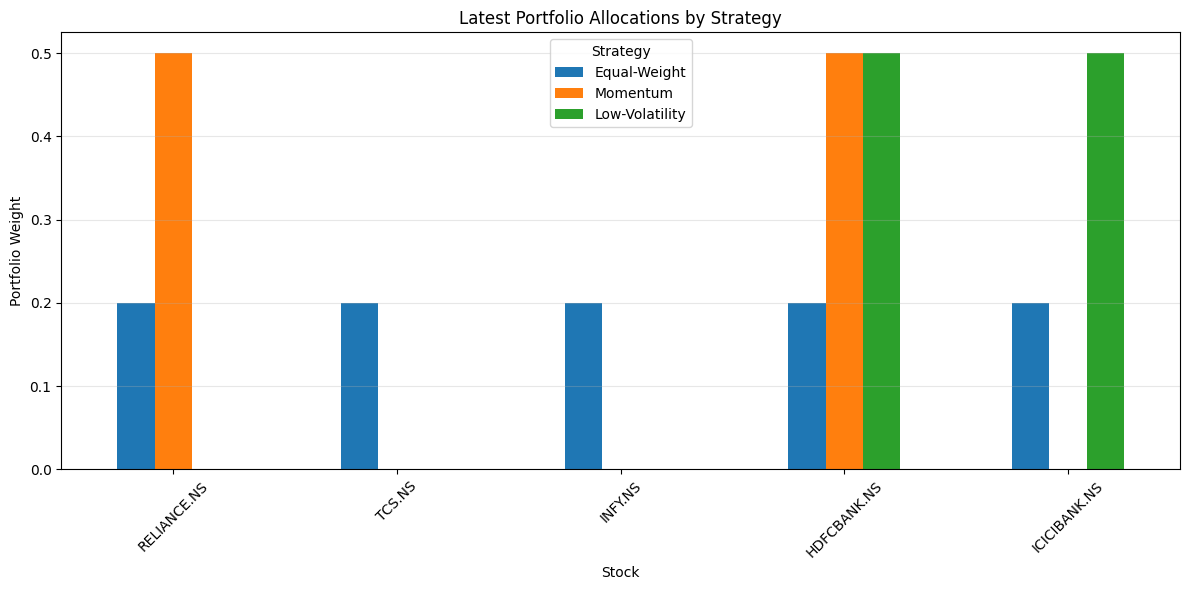

In [5]:

# Align both factor signals with the daily return dates
momentum_aligned = momentum_signal.reindex(daily_returns.index)
volatility_aligned = rolling_volatility.reindex(daily_returns.index)

# Define the number of stocks selected by each factor strategy
number_selected = 2

# Create target weights, initially missing until valid signals are available
momentum_target_weights = pd.DataFrame(
    np.nan,
    index=daily_returns.index,
    columns=stocks
)

low_vol_target_weights = pd.DataFrame(
    np.nan,
    index=daily_returns.index,
    columns=stocks
)

# Identify the final available trading date of each month
monthly_dates = (
    pd.Series(daily_returns.index, index=daily_returns.index)
    .groupby(daily_returns.index.to_period("M"))
    .last()
    .tolist()
)

# Construct target allocations at each monthly signal date
for date in monthly_dates:
    momentum_row = momentum_aligned.loc[date].dropna()
    volatility_row = volatility_aligned.loc[date].dropna()

    # Momentum: select the stocks with the highest signals
    if len(momentum_row) >= number_selected:
        selected_momentum = momentum_row.nlargest(
            number_selected
        ).index

        momentum_target_weights.loc[date, :] = 0.0
        momentum_target_weights.loc[
            date, selected_momentum
        ] = 1.0 / number_selected

    # Low volatility: select the stocks with the lowest volatility
    if len(volatility_row) >= number_selected:
        selected_low_vol = volatility_row.nsmallest(
            number_selected
        ).index

        low_vol_target_weights.loc[date, :] = 0.0
        low_vol_target_weights.loc[
            date, selected_low_vol
        ] = 1.0 / number_selected

# Carry each monthly allocation forward until the next rebalance.
# Shift by one trading day so weights are applied only to subsequent returns.
momentum_weights = momentum_target_weights.ffill().shift(1)
low_vol_weights = low_vol_target_weights.ffill().shift(1)

# Equal-weight benchmark
equal_weight_weights = pd.DataFrame(
    1.0 / len(stocks),
    index=daily_returns.index,
    columns=stocks
)

# Display the latest target allocations
latest_momentum_weights = (
    momentum_target_weights.dropna(how="all").iloc[-1]
)

latest_low_vol_weights = (
    low_vol_target_weights.dropna(how="all").iloc[-1]
)

allocation_table = pd.DataFrame({
    "Equal-Weight": equal_weight_weights.iloc[-1],
    "Momentum": latest_momentum_weights,
    "Low-Volatility": latest_low_vol_weights
})

print("Latest target portfolio allocations:")
display(allocation_table)

print("\nMomentum portfolio weight sum:",
      round(latest_momentum_weights.sum(), 4))

print("Low-volatility portfolio weight sum:",
      round(latest_low_vol_weights.sum(), 4))

# Plot the latest target allocations
allocation_table.plot(
    kind="bar",
    figsize=(12, 6),
    title="Latest Portfolio Allocations by Strategy"
)

plt.xlabel("Stock")
plt.ylabel("Portfolio Weight")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()



## 5. Historical Portfolio Performance

In this section, we evaluate the historical performance of the equal-weight, momentum, and low-volatility portfolios using daily stock returns.

### 5.1 Portfolio Returns

For a portfolio with weights $$w_{i,t}$$, the daily portfolio return is calculated as:

$$
R_{p,t} = \sum_{i=1}^{N} w_{i,t}r_{i,t}
$$

where:

- \(w_{i,t}\) is the portfolio weight assigned to stock \(i\) before the return at time \(t\).
- \(r_{i,t}\) is the daily return of stock \(i\).
- \(N\) is the number of stocks in the universe.

The weights remain constant between monthly rebalancing dates.

### 5.2 Cumulative Growth

The cumulative growth of an investment is calculated by compounding daily returns:

$$
G_t = \prod_{s=1}^{t}(1+R_{p,s})
$$

A starting value of 1 represents the initial investment. For example, a growth value of 1.20 corresponds to a cumulative return of 20%.

### 5.3 Comparison of Strategies

We compare the growth paths of the three portfolios to examine differences in historical performance. The equal-weight portfolio serves as a simple benchmark, while the momentum and low-volatility portfolios represent systematic factor-based allocation rules.

The comparison is preliminary because transaction costs, market impact, and other implementation constraints have not yet been included.


Portfolio return preview:


,Equal-Weight,Momentum,Low-Volatility
Date,,,
2021-02-01,0.048404,0.013317,0.035514
2021-02-02,0.024781,0.014313,0.038582
2021-02-03,0.005846,0.004740,0.004035
2021-02-04,0.000250,-0.003875,-0.000447
2021-02-05,-0.005265,-0.007617,0.001075



Cumulative growth preview:


,Equal-Weight,Momentum,Low-Volatility
Date,,,
2021-02-01,1.048404,1.013317,1.035514
2021-02-02,1.074385,1.027821,1.075466
2021-02-03,1.080666,1.032692,1.079806
2021-02-04,1.080936,1.028691,1.079323
2021-02-05,1.075245,1.020855,1.080483


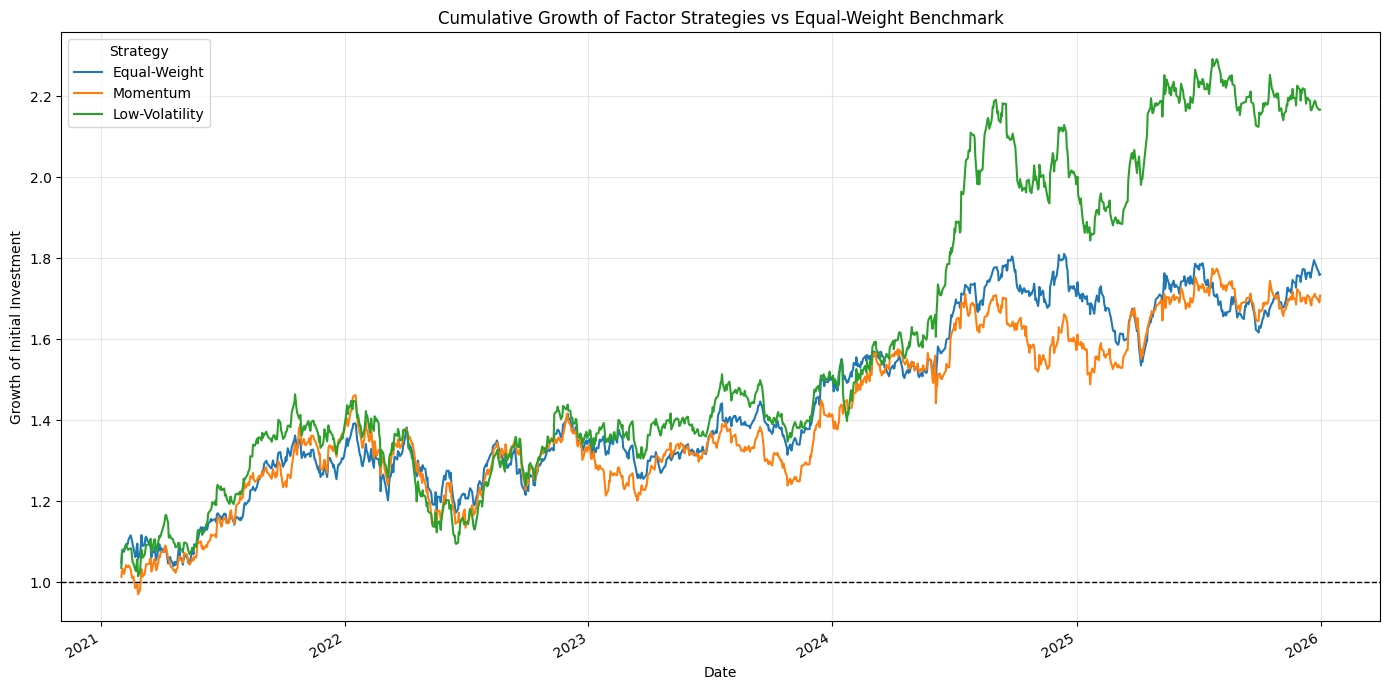

Cumulative returns over the evaluated period:


,Cumulative Return (%)
Equal-Weight,76.02
Momentum,70.81
Low-Volatility,116.71


In [6]:

# Calculate daily portfolio returns using weights established
# before the corresponding daily returns occur.

equal_weight_returns = (
    equal_weight_weights * daily_returns
).sum(axis=1, min_count=len(stocks))

momentum_returns = (
    momentum_weights * daily_returns
).sum(axis=1, min_count=len(stocks))

low_vol_returns = (
    low_vol_weights * daily_returns
).sum(axis=1, min_count=len(stocks))

# Combine portfolio returns into a single DataFrame
portfolio_returns = pd.DataFrame({
    "Equal-Weight": equal_weight_returns,
    "Momentum": momentum_returns,
    "Low-Volatility": low_vol_returns
})

# Remove dates when any strategy lacks valid portfolio weights
portfolio_returns = portfolio_returns.dropna()

if portfolio_returns.empty:
    raise ValueError(
        "No valid portfolio returns were generated. "
        "Check the signal dates and portfolio weights."
    )

# Calculate cumulative growth from an initial investment of 1
cumulative_growth = (1 + portfolio_returns).cumprod()

print("Portfolio return preview:")
display(portfolio_returns.head())

print("\nCumulative growth preview:")
display(cumulative_growth.head())

# Plot cumulative growth
cumulative_growth.plot(
    figsize=(14, 7),
    title="Cumulative Growth of Factor Strategies vs Equal-Weight Benchmark"
)

plt.axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Date")
plt.ylabel("Growth of Initial Investment")
plt.grid(True, alpha=0.3)
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()

# Report total cumulative return over the evaluated period
total_returns = cumulative_growth.iloc[-1] - 1

print("Cumulative returns over the evaluated period:")
display(
    (total_returns * 100)
    .rename("Cumulative Return (%)")
    .to_frame()
    .round(2)
)



## 6. Risk-Adjusted Performance Evaluation

Cumulative returns show how the portfolios grew over the evaluation period, but they do not fully describe the risk taken to achieve those returns. We therefore calculate several complementary performance metrics.

### 6.1 Annualized Return

The annualized return estimates the compounded rate of growth over a one-year period:

$$
R_{\text{ann}} =
\left(\prod_{t=1}^{T}(1+R_{p,t})\right)^{252/T}-1
$$

where \(T\) is the number of daily observations and 252 is the approximate number of trading days in a year.

### 6.2 Annualized Volatility

Annualized volatility estimates the variability of daily returns on an annual basis:

$$
\sigma_{\text{ann}} = \sigma_{\text{daily}}\sqrt{252}
$$

### 6.3 Sharpe Ratio

The Sharpe ratio measures excess return per unit of return volatility:

$$
S = \frac{R_{\text{ann}}-R_{f,\text{ann}}}{\sigma_{\text{ann}}}
$$

For this initial comparison, the annual risk-free rate is assumed to be zero. This simplifying assumption will be stated explicitly when interpreting the results.

### 6.4 Maximum Drawdown

Maximum drawdown measures the largest peak-to-trough decline in cumulative portfolio value:

$$
D_t = \frac{G_t}{\max_{s\leq t}G_s}-1
$$

$$
D_{\max} = \min_t D_t
$$

A more negative maximum drawdown indicates a deeper historical loss from a previous peak.

### 6.5 Interpretation

No single metric fully captures investment performance. Annualized return measures growth, volatility measures variability, the Sharpe ratio summarizes return relative to volatility, and maximum drawdown describes the severity of the largest historical decline.

All results are historical estimates and do not guarantee future performance.


Portfolio performance comparison
Percentage-based metrics are expressed in percent.
Sharpe ratio is annualized from daily excess returns; annual risk-free rate assumed to be 0%.


,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
Equal-Weight,76.02,12.43,15.33,0.84,-15.89
Momentum,70.81,11.73,17.18,0.73,-22.61
Low-Volatility,116.71,17.38,17.62,1.00,-25.24


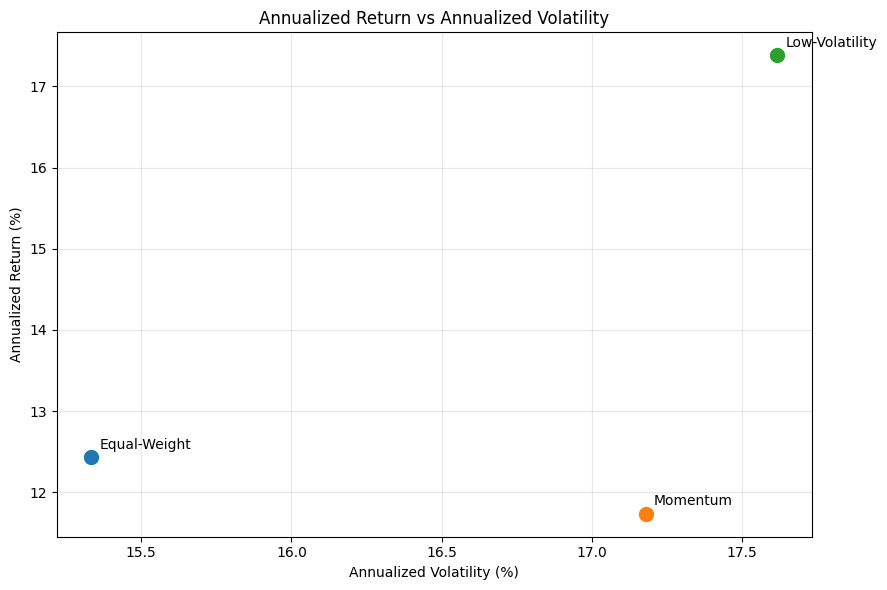

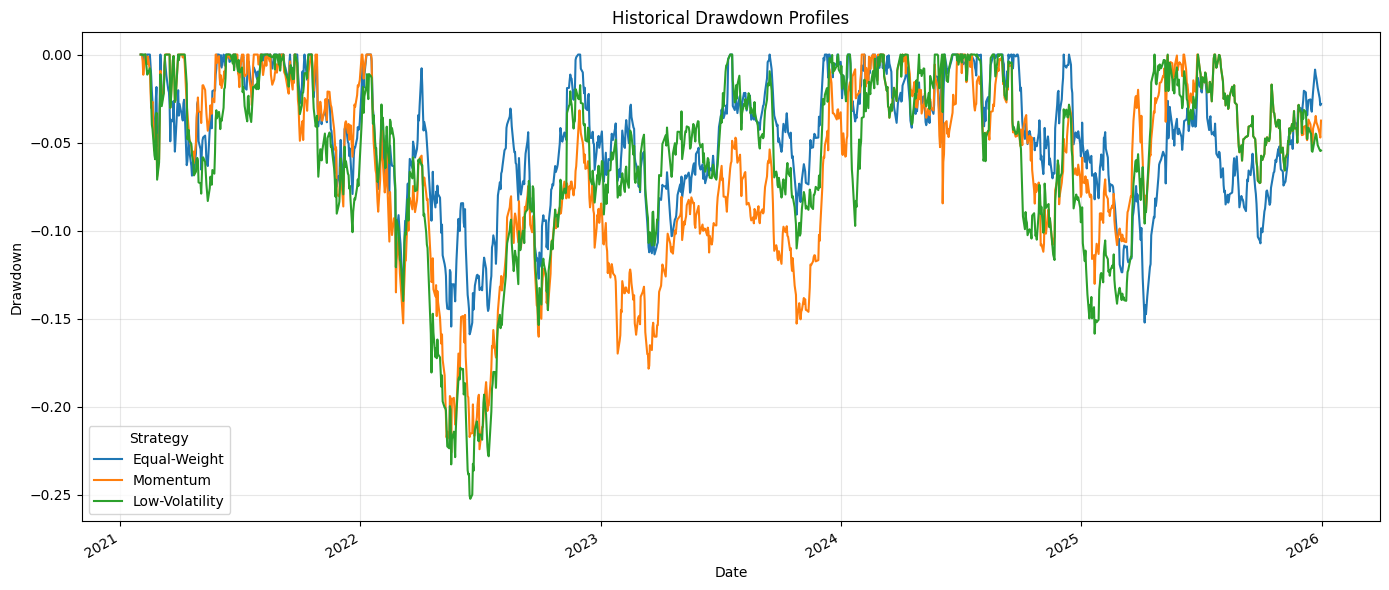

In [7]:

# Define annualization and risk-free-rate assumptions
trading_days_per_year = 252
annual_risk_free_rate = 0.0

# Calculate performance metrics for each portfolio
performance_metrics = {}

for strategy in portfolio_returns.columns:
    returns = portfolio_returns[strategy].dropna()

    # Skip empty return series
    if returns.empty:
        continue

    number_of_observations = len(returns)

    # Total cumulative return
    cumulative_return = (1 + returns).prod() - 1

    # Annualized compounded return
    annualized_return = (
        (1 + cumulative_return)
        ** (trading_days_per_year / number_of_observations)
        - 1
    )

    # Annualized volatility
    annualized_volatility = (
        returns.std(ddof=1) * np.sqrt(trading_days_per_year)
    )

    # Convert the annual risk-free rate to an equivalent daily rate.
    # The conventional annualized Sharpe ratio uses mean daily excess return.
    daily_risk_free_rate = (
        (1 + annual_risk_free_rate) ** (1 / trading_days_per_year) - 1
    )

    daily_volatility = returns.std(ddof=1)

    if daily_volatility > 0:
        sharpe_ratio = (
            (returns.mean() - daily_risk_free_rate)
            / daily_volatility
            * np.sqrt(trading_days_per_year)
        )
    else:
        sharpe_ratio = np.nan

    # Maximum drawdown
    growth = (1 + returns).cumprod()
    running_peak = growth.cummax()
    drawdown = growth / running_peak - 1
    maximum_drawdown = drawdown.min()

    performance_metrics[strategy] = {
        "Cumulative Return": cumulative_return,
        "Annualized Return": annualized_return,
        "Annualized Volatility": annualized_volatility,
        "Sharpe Ratio": sharpe_ratio,
        "Maximum Drawdown": maximum_drawdown
    }

performance_table = pd.DataFrame(performance_metrics).T

# Format the table for readability
percentage_columns = [
    "Cumulative Return",
    "Annualized Return",
    "Annualized Volatility",
    "Maximum Drawdown"
]

formatted_performance = performance_table.copy()

for column in percentage_columns:
    formatted_performance[column] = (
        formatted_performance[column] * 100
    )

print("Portfolio performance comparison")
print("Percentage-based metrics are expressed in percent.")
print("Sharpe ratio is annualized from daily excess returns; annual risk-free rate assumed to be 0%.")

display(formatted_performance.round(2))

# Plot annualized return versus annualized volatility
plt.figure(figsize=(9, 6))

for strategy, row in performance_table.iterrows():
    plt.scatter(
        row["Annualized Volatility"] * 100,
        row["Annualized Return"] * 100,
        s=100
    )
    plt.annotate(
        strategy,
        (
            row["Annualized Volatility"] * 100,
            row["Annualized Return"] * 100
        ),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.title("Annualized Return vs Annualized Volatility")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Annualized Return (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot drawdown profiles
growth_curves = (1 + portfolio_returns).cumprod()
running_peaks = growth_curves.cummax()
drawdown_curves = growth_curves / running_peaks - 1

drawdown_curves.plot(
    figsize=(14, 6),
    title="Historical Drawdown Profiles"
)

plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.grid(True, alpha=0.3)
plt.legend(title="Strategy")
plt.tight_layout()
plt.show()



## 7. Results, Discussion, and Limitations

This section summarizes the results obtained from the equal-weight benchmark, momentum strategy, and low-volatility strategy. The comparison uses cumulative returns, annualized returns, annualized volatility, Sharpe ratios, and maximum drawdown.

### 7.1 Interpretation of Results

The cumulative growth chart illustrates how the value of each portfolio evolved over the evaluation period. Differences between the growth paths indicate how the portfolio construction rules affected historical performance.

The performance table provides additional information about the relationship between return and risk:

- **Cumulative Return:** Measures the total growth or decline in portfolio value over the evaluation period.
- **Annualized Return:** Estimates the compounded annual rate of return.
- **Annualized Volatility:** Measures the annualized variability of daily portfolio returns.
- **Sharpe Ratio:** Measures annualized excess return per unit of annualized volatility. A higher value indicates better return relative to volatility under the assumptions used.
- **Maximum Drawdown:** Measures the largest peak-to-trough decline in portfolio value.

### 7.2 Momentum Strategy

The momentum strategy selects stocks with the strongest historical price performance over the specified lookback period, excluding the most recent month.

Its effectiveness depends on whether historical relative performance persists into subsequent periods. Momentum may perform poorly during sharp market reversals, when previously underperforming stocks recover rapidly.

The observed performance should therefore be evaluated alongside volatility and maximum drawdown rather than by cumulative return alone.

### 7.3 Low-Volatility Strategy

The low-volatility strategy selects stocks with the lowest estimated historical volatility over the rolling estimation window.

Its objective is to construct a portfolio with relatively low historical risk. However, lower past volatility does not guarantee lower future volatility or higher returns.

The strategy's effectiveness must be assessed using the realized performance metrics and compared with the equal-weight benchmark.

### 7.4 Limitations of the Analysis

The following limitations should be considered when interpreting the results:

1. **Limited stock universe:** The analysis uses only five Indian stocks, so the findings may not generalize to the wider equity market.
2. **Historical estimation:** Factor signals are calculated from past data and may not predict future returns.
3. **Transaction costs:** Brokerage, taxes, bid-ask spreads, and market impact are not included in the preliminary backtest.
4. **Parameter sensitivity:** The results may change if the lookback periods, skip period, number of selected stocks, or rebalancing frequency are modified.
5. **Market conditions:** The evaluation period may not represent all market environments.
6. **Implementation assumptions:** The timing of signals and portfolio weights must be handled consistently to avoid look-ahead bias.

### 7.5 Conclusion

This notebook extends the portfolio optimization analysis by introducing two systematic stock-selection approaches: momentum and low volatility.

The strategies use explicit ranking rules to translate historical market data into portfolio allocations. Their performance is compared with a simple equal-weight benchmark using both return-based and risk-adjusted metrics.

No strategy should be declared superior without examining its realized results, implementation costs, and robustness across different periods. Further analysis should include transaction costs, out-of-sample evaluation, and sensitivity testing before drawing stronger conclusions about the practical usefulness of either factor.


In [8]:

# Section 8: Automated Strategy Comparison and Conclusion

# Check that the performance table exists and contains valid results
if "performance_table" not in globals() or performance_table.empty:
    raise ValueError(
        "Performance table not found. Run Cell 14 before this cell."
    )

required_metrics = [
    "Annualized Return",
    "Annualized Volatility",
    "Sharpe Ratio",
    "Maximum Drawdown"
]

missing_metrics = [
    metric for metric in required_metrics
    if metric not in performance_table.columns
]

if missing_metrics:
    raise ValueError(
        f"Missing required performance metrics: {missing_metrics}"
    )

# Remove strategies with incomplete results
results = performance_table[required_metrics].dropna(
    subset=["Annualized Return", "Annualized Volatility"]
)

if results.empty:
    raise ValueError(
        "No valid strategy results are available for comparison."
    )

print("=" * 65)
print("AUTOMATED FACTOR STRATEGY COMPARISON")
print("=" * 65)

# Identify the best strategy for each metric
best_return_strategy = results["Annualized Return"].idxmax()
lowest_volatility_strategy = results["Annualized Volatility"].idxmin()

valid_sharpe = results["Sharpe Ratio"].dropna()
best_sharpe_strategy = (
    valid_sharpe.idxmax() if not valid_sharpe.empty else None
)

valid_drawdown = results["Maximum Drawdown"].dropna()
best_drawdown_strategy = (
    valid_drawdown.idxmax() if not valid_drawdown.empty else None
)

# Display the results
print(
    f"\nHighest annualized return: {best_return_strategy} "
    f"({results.loc[best_return_strategy, 'Annualized Return']:.2%})"
)

print(
    f"Lowest annualized volatility: {lowest_volatility_strategy} "
    f"({results.loc[lowest_volatility_strategy, 'Annualized Volatility']:.2%})"
)

if best_sharpe_strategy is not None:
    print(
        f"Highest Sharpe ratio: {best_sharpe_strategy} "
        f"({results.loc[best_sharpe_strategy, 'Sharpe Ratio']:.3f})"
    )
else:
    print("Highest Sharpe ratio: unavailable")

if best_drawdown_strategy is not None:
    print(
        f"Least severe maximum drawdown: {best_drawdown_strategy} "
        f"({results.loc[best_drawdown_strategy, 'Maximum Drawdown']:.2%})"
    )
else:
    print("Maximum drawdown comparison: unavailable")

# Generate a concise, data-driven conclusion
print("\n" + "=" * 65)
print("CONCLUSION")
print("=" * 65)

print(
    f"The {best_return_strategy} strategy achieved the highest "
    "annualized return over the evaluated period."
)

print(
    f"The {lowest_volatility_strategy} strategy recorded the "
    "lowest annualized volatility."
)

if best_sharpe_strategy is not None:
    print(
        f"The {best_sharpe_strategy} strategy achieved the highest "
        "Sharpe ratio using the annualized daily-excess-return convention and a zero risk-free rate."
    )

if best_drawdown_strategy is not None:
    print(
        f"The {best_drawdown_strategy} strategy experienced the "
        "least severe maximum drawdown among the strategies compared."
    )

print(
    "\nThese conclusions describe historical results only. "
    "They do not establish that a strategy will outperform in the future. "
    "Transaction costs, parameter sensitivity, and out-of-sample "
    "performance should be investigated before practical implementation."
)


AUTOMATED FACTOR STRATEGY COMPARISON

Highest annualized return: Low-Volatility (17.38%)
Lowest annualized volatility: Equal-Weight (15.33%)
Highest Sharpe ratio: Low-Volatility (0.998)
Least severe maximum drawdown: Equal-Weight (-15.89%)

CONCLUSION
The Low-Volatility strategy achieved the highest annualized return over the evaluated period.
The Equal-Weight strategy recorded the lowest annualized volatility.
The Low-Volatility strategy achieved the highest Sharpe ratio using the annualized daily-excess-return convention and a zero risk-free rate.
The Equal-Weight strategy experienced the least severe maximum drawdown among the strategies compared.

These conclusions describe historical results only. They do not establish that a strategy will outperform in the future. Transaction costs, parameter sensitivity, and out-of-sample performance should be investigated before practical implementation.
